<a href="https://colab.research.google.com/github/zakariarajeb-crypto/SIMA2026/blob/main/Copia_di_L05_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L5 — Raggruppare, riassumere, disegnare

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/lezioni/L05_raggruppare/L05_task.ipynb)

## Contesto

Il dataset è pulito (è il risultato della L3). Ora possiamo finalmente fare domande da economisti: come va il fatturato nel tempo? Quale regione ha le imprese più grandi? Quale settore è più produttivo?

**La domanda di oggi:** il numero che ottieni racconta davvero quello che sembra?

## 0. Preparazione

Esegui questa cella così com'è: carica il dataset pulito e la libreria per i grafici.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/imprese_pulito.xlsx")
df.shape
df.head(5)

,id_impresa,ragione_sociale,regione,settore,data_costituzione,anno,addetti,fatturato,spesa_rs
0,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2019,10.0,1032.9,37.1
1,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2020,10.0,749.6,NaN
2,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2021,11.0,1094.2,33.9
3,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2022,12.0,1299.4,71.9
4,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2023,11.0,1304.1,55.8


## Parte 1 — Nuove colonne

### 1. La produttività

Crea una nuova colonna `produttivita`: fatturato diviso addetti (migliaia di euro per addetto). Poi mostra le prime 5 righe per controllare.

🔎 *Da cercare:* `pandas nuova colonna` · `pandas dividere colonne`

In [ ]:
produttivita=df["fatturato"]/df["addetti"]
df["produttivita"]=produttivita.round(3)
df.head(5)

,id_impresa,ragione_sociale,regione,settore,data_costituzione,anno,addetti,fatturato,spesa_rs,produttivita
0,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2019,10.0,1032.9,37.1,103.290
1,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2020,10.0,749.6,NaN,74.960
2,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2021,11.0,1094.2,33.9,99.473
3,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2022,12.0,1299.4,71.9,108.283
4,IMP0001,Linea Group S.r.l.,Emilia-Romagna,Alloggio e ristorazione,1969-05-19,2023,11.0,1304.1,55.8,118.555


### 2. Controllala

Quanti valori mancanti ha `produttivita`? Sono di più di quelli di `fatturato`? Perché?

🔎 *Da cercare:* `pandas isna sum`

In [ ]:
produttivita_mancanti=df["produttivita"].isna().sum()
fatturato_mancanti=df["fatturato"].isna().sum()
df.head(5)
print("produttivita mancanti:", produttivita_mancanti)
print("fatturato mancanti:", fatturato_mancanti)


produttivita mancanti: 125
fatturato mancanti: 50


*Risposta:* ...

## Parte 2 — Raggruppare

### 3. Fatturato medio per anno

Calcola il fatturato **medio** per ogni anno.

🔎 *Da cercare:* `pandas groupby mean`

In [ ]:
fatturato_medio=df.groupby("anno")["fatturato"].mean().round(2)
fatturato_medio

,fatturato
anno,
2019,2674.62
2020,1952.35
2021,2732.86
2022,2802.15
2023,2869.68


### 4. Più statistiche insieme

Per ogni anno calcola media, mediana e numero di osservazioni del fatturato, in un'unica tabella.

🔎 *Da cercare:* `pandas groupby agg`

In [ ]:
statistiche=df.groupby("anno")["fatturato"].agg(["mean", "median", "count"])
statistiche



,mean,median,count
anno,,,
2019,2674.625000,1435.90,488
2020,1952.345732,1054.15,492
2021,2732.856911,1457.65,492
2022,2802.149592,1466.95,490
2023,2869.680123,1523.45,488


### 5. La regione più ricca?

Calcola il fatturato medio per regione e ordinalo dal più alto al più basso. Quale regione è prima?

🔎 *Da cercare:* `pandas sort_values ascending`

In [ ]:
Regione_ricca = (
    df.groupby("regione")["fatturato"].mean().sort_values(ascending=False).round(2))
Regione_ricca

,fatturato
regione,
Liguria,7024.93
Basilicata,5387.35
Calabria,3996.43
Umbria,3909.29
Emilia-Romagna,3270.82
Lazio,2807.93
Sicilia,2742.05
Friuli-Venezia Giulia,2719.22
Sardegna,2626.90


### 6. Ne sei sicuro?

Rifai la tabella per regione con **media**, **mediana** e **numero di imprese diverse**. La classifica regge? Guarda in particolare le prime due regioni.

🔎 *Da cercare:* `pandas agg named aggregation` · `pandas nunique`

In [ ]:
Verifica = (
    df.groupby("regione")
    .agg({
        "fatturato": ["mean", "median", "count"],
        "id_impresa": ["count", "nunique"]
    })
    .sort_values(
        by=[("fatturato", "mean"), ("id_impresa", "nunique")],
        ascending=False
    )
).round(2)
Verifica

fatturato                id_impresa        
                           mean   median count      count nunique
regione                                                          
Liguria                 7024.93  1591.00    80         80      16
Basilicata              5387.35  4420.40    10         10       2
Calabria                3996.43  1560.20   120        125      25
Umbria                  3909.29  2396.45    64         65      13
Emilia-Romagna          3270.82  1677.25   188        190      38
Lazio                   2807.93  1266.85   268        275      55
Sicilia                 2742.05  1396.80   125        125      25
Friuli-Venezia Giulia   2719.22  1759.15    40         40       8
Sardegna                2626.90  1773.50    60         60      12
Toscana                 2425.58  1408.55   176        180      36
Campania                2271.41  1233.30   155        160      32
Piemonte                2118.39  1215.05   120        125      25
Lombardia               2069.43  1425.50   388        395      79
Trentino-Alto Adige     2060.15  1585.50    67         70      14
Veneto                  2027.41  1313.20   211        215      43
Abruzzo                 1931.10  1760.50    75         75      15
Marche                  1887.68  1339.20    64         65      13
Valle d'Aosta           1664.17  1671.25    44         45       9
Molise                  1655.49  1078.55    20         20       4
Puglia                  1643.85  1005.70   175        180      36

*Risposta:* ...

### 7. I settori

Calcola la produttività **mediana** per settore, ordinata. Quale settore è il più produttivo?

🔎 *Da cercare:* `pandas groupby median`

In [ ]:
Cl_produttività=df.groupby("settore")["fatturato"].agg("median").sort_values(ascending=False)
Cl_produttività

,fatturato
settore,
Manifattura,1876.9
Costruzioni,1492.4
Agroalimentare,1480.1
Trasporti,1447.4
Servizi ICT,1339.6
Commercio,1140.6
Alloggio e ristorazione,1107.3


## Parte 3 — Disegnare

### 8. Nel tempo

Disegna un grafico a **linea** del fatturato **mediano** per anno. Cosa succede nel 2020?

🔎 *Da cercare:* `pandas plot line`

In [ ]:
# scrivi qui il tuo codice


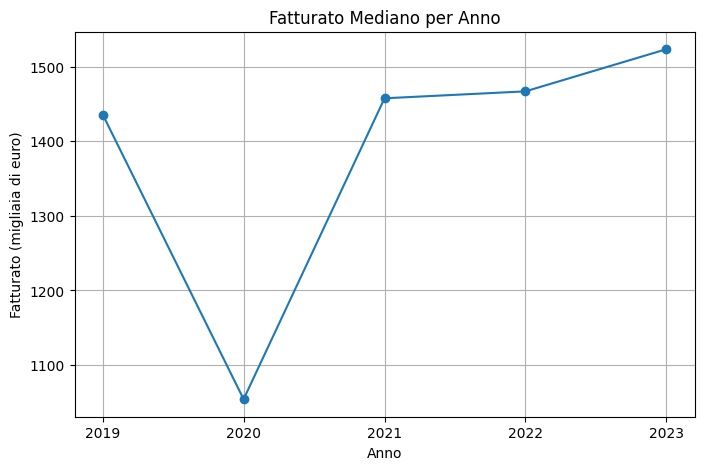

In [ ]:
# Calcoliamo il fatturato mediano per anno
fatturato_mediano = df.groupby('anno')['fatturato'].median()

# Disegniamo il grafico a linea
fatturato_mediano.plot(kind='line', marker='o', figsize=(8, 5))
plt.title('Fatturato Mediano per Anno')
plt.xlabel('Anno')
plt.ylabel('Fatturato (migliaia di euro)')
plt.grid(True)
plt.xticks(fatturato_mediano.index)  # Mostra solo gli anni effettivi sull'asse X
plt.show()

*Risposta:* ...

### 9. Per categoria

Disegna un grafico a **barre orizzontali** della produttività mediana per settore, ordinate.

🔎 *Da cercare:* `pandas plot barh`

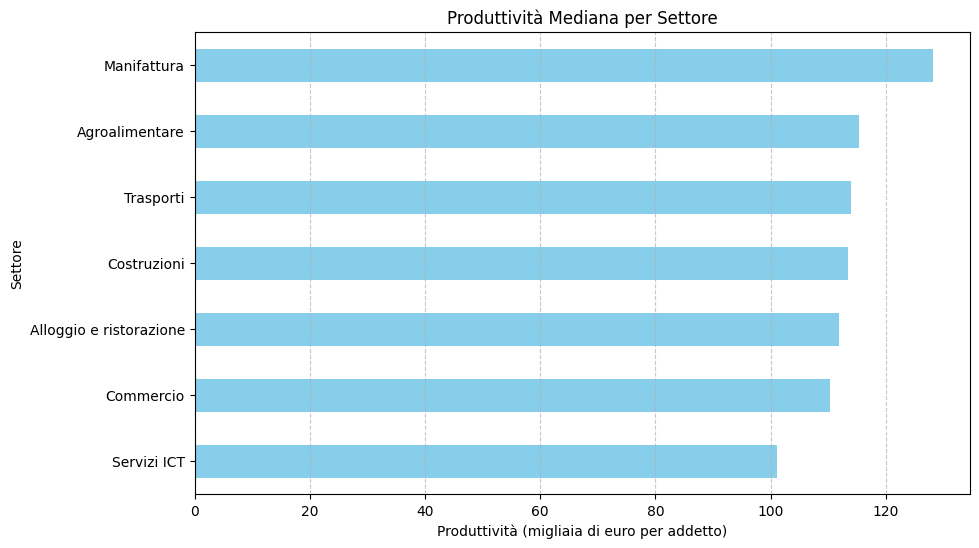

In [ ]:
# Calcoliamo la produttività mediana per settore e ordiniamola
produttivita_settore = df.groupby('settore')['produttivita'].median().sort_values()

# Creiamo il grafico a barre orizzontali
produttivita_settore.plot(kind='barh', figsize=(10, 6), color='skyblue')
plt.title('Produttività Mediana per Settore')
plt.xlabel('Produttività (migliaia di euro per addetto)')
plt.ylabel('Settore')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

### 10. La distribuzione

Disegna un **istogramma** del fatturato. Che forma ha? Ti spiega perché media e mediana sono così diverse?

🔎 *Da cercare:* `pandas plot hist bins`

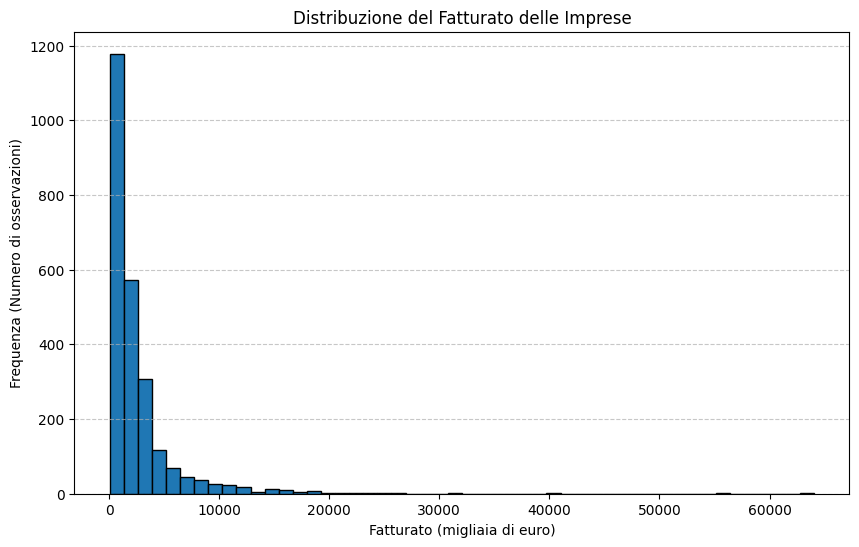

In [ ]:
# Disegniamo l'istogramma del fatturato
df['fatturato'].plot(kind='hist', bins=50, figsize=(10, 6), edgecolor='black')
plt.title('Distribuzione del Fatturato delle Imprese')
plt.xlabel('Fatturato (migliaia di euro)')
plt.ylabel('Frequenza (Numero di osservazioni)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

*Risposta:* ...

## Domanda finale

Un giornalista ti chiede: *"Qual è la regione con le imprese più ricche?"* Scrivi una frase che gli diresti, e una che **non** gli diresti.

*Risposta:*
- Direi: ...
- Non direi: ...

---
## ⭐ Bonus (per chi ha finito)

### B1. Un grafico presentabile

Riprendi il grafico nel tempo e aggiungi titolo, etichette degli assi con le unità di misura, e salvalo come immagine `fatturato_anno.png`.

🔎 *Da cercare:* `matplotlib title xlabel ylabel` · `matplotlib savefig`

In [ ]:
# scrivi qui il tuo codice


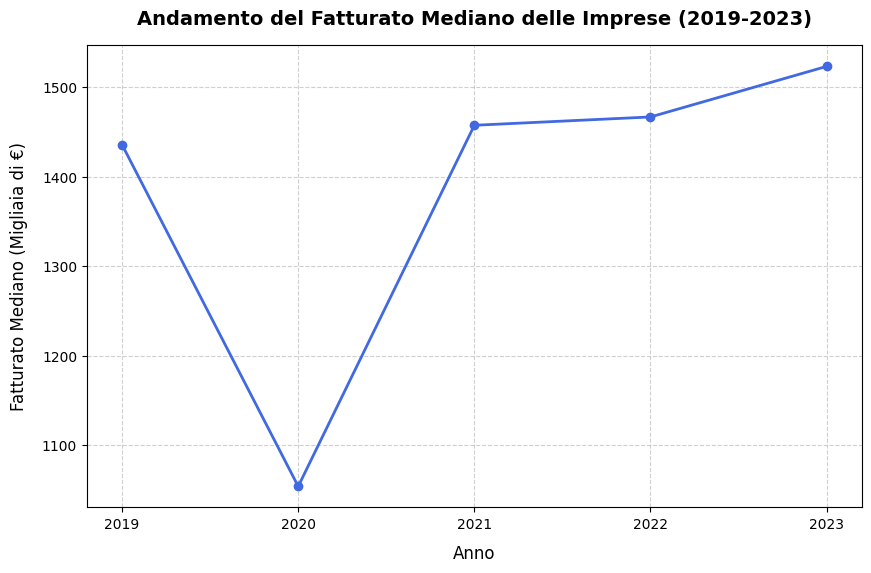

In [ ]:
# Calcoliamo il fatturato mediano per anno
fatturato_mediano = df.groupby('anno')['fatturato'].median()

# Impostiamo le dimensioni del grafico
plt.figure(figsize=(10, 6))

# Creiamo il grafico a linee
plt.plot(fatturato_mediano.index, fatturato_mediano.values, marker='o', color='royalblue', linewidth=2, label='Fatturato Mediano')

# Aggiungiamo titolo ed etichette con unità di misura
plt.title('Andamento del Fatturato Mediano delle Imprese (2019-2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Anno', fontsize=12, labelpad=10)
plt.ylabel('Fatturato Mediano (Migliaia di €)', fontsize=12, labelpad=10)

# Personalizziamo la griglia e i valori degli assi
plt.xticks(fatturato_mediano.index)
plt.grid(True, linestyle='--', alpha=0.6)

# Salviamo il grafico come immagine PNG
plt.savefig('fatturato_anno.png', dpi=300, bbox_inches='tight')

# Mostriamo il grafico
plt.show()

### B2. Una tabella a doppia entrata

Costruisci una tabella con le regioni sulle righe, gli anni sulle colonne e il fatturato mediano nelle celle.

🔎 *Da cercare:* `pandas pivot_table`

In [ ]:
# Creiamo la tabella a doppia entrata (pivot_table)
tabella_doppia = df.pivot_table(
    values='fatturato',
    index='regione',
    columns='anno',
    aggfunc='median'
).round(2)

# Mostriamo la tabella
display(tabella_doppia)

anno,2019,2020,2021,2022,2023
regione,,,,,
Abruzzo,1747.70,1477.10,2129.40,2100.10,2257.20
Basilicata,4980.30,4281.20,5151.55,6183.65,6340.05
Calabria,1832.70,1045.90,1842.30,1756.15,1683.70
Campania,1321.20,1103.70,1306.30,1321.20,1377.05
Emilia-Romagna,1577.60,1192.05,1733.00,1738.40,1806.60
Friuli-Venezia Giulia,2125.70,1529.70,2227.70,1956.15,1946.95
Lazio,1302.70,1022.65,1242.40,1386.10,1430.00
Liguria,1461.70,1296.65,1588.15,1623.65,1750.70
Lombardia,1403.80,1046.75,1447.45,1490.80,1614.90


### B3. Scala logaritmica

Rifai l'istogramma del fatturato con l'asse orizzontale in scala logaritmica. Cosa cambia?

🔎 *Da cercare:* `numpy log` · `matplotlib xscale log`

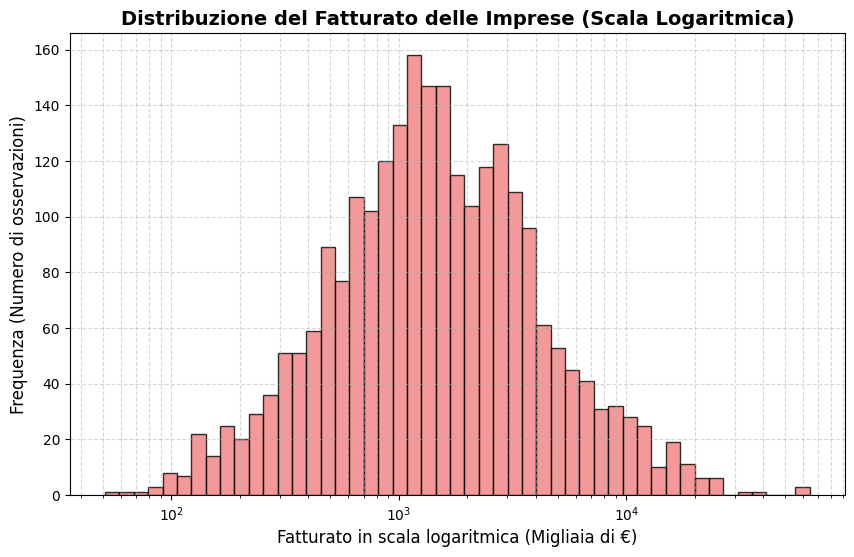

In [ ]:
import numpy as np

# Creiamo l'istogramma con asse X logaritmico
plt.figure(figsize=(10, 6))

# Definiamo dei bin equispaziati in scala logaritmica
bins_log = np.logspace(np.log10(df['fatturato'].min()), np.log10(df['fatturato'].max()), 50)

# Disegniamo l'istogramma
plt.hist(df['fatturato'], bins=bins_log, edgecolor='black', color='lightcoral', alpha=0.8)

# Impostiamo la scala logaritmica sull'asse X
plt.xscale('log')

# Titolo e dettagli estetici
plt.title('Distribuzione del Fatturato delle Imprese (Scala Logaritmica)', fontsize=14, fontweight='bold')
plt.xlabel('Fatturato in scala logaritmica (Migliaia di €)', fontsize=12)
plt.ylabel('Frequenza (Numero di osservazioni)', fontsize=12)
plt.grid(True, which="both", linestyle='--', alpha=0.5)

plt.show()

### B4. La crescita di ogni impresa

Il dataset è un **panel**: le stesse imprese, anno dopo anno. Calcola la crescita % del fatturato di ogni impresa rispetto all'anno prima, in una nuova colonna `crescita`. Attenzione: ogni impresa va confrontata con **se stessa**, non con la riga sopra (che per il primo anno è un'altra impresa). Poi calcola la crescita mediana per anno: quale anno è andato peggio? Perché il 2019 è vuoto?

🔎 *Da cercare:* `pandas sort_values più colonne` · `pandas groupby pct_change`

In [ ]:
# scrivi qui il tuo codice


*Risposta:* ...

---
## 📊 Per casa: altri grafici

Quattro esercizi sui grafici, da fare a casa prima della L6. Ripartono tutti da `df` con la colonna `produttivita` (Parte 1): se hai riavviato la sessione, riesegui prima la Preparazione e il passo 1.

Per ogni grafico, chiediti: **cosa si vede al primo sguardo? È vero?**

### D1. Media e mediana nello stesso grafico

Disegna in un unico grafico a linea **due linee**: il fatturato medio e quello mediano, anno per anno. Suggerimento: se `agg` restituisce una tabella con due colonne, `plot` disegna una linea per colonna, con la legenda. Aggiungi titolo e unità di misura.

1. Le due linee raccontano la stessa storia? Perché sono così lontane?
2. Guarda l'asse orizzontale: esiste l'anno 2019,5? Fai in modo che compaiano solo gli anni veri.
3. La legenda è in inglese (`mean`, `median`): fai in modo che dica `media` e `mediana`.

🔎 *Da cercare:* `pandas groupby agg` · `matplotlib xticks` · `pandas agg named aggregation`

In [ ]:
# scrivi qui il tuo codice


*Risposta:* ...

### D2. Una linea per settore

Costruisci una tabella con gli anni sulle righe, i settori sulle colonne e il fatturato **mediano** nelle celle (è la tabella a doppia entrata del bonus B2), poi disegnala: una linea per settore.

1. Tutti i settori crollano nel 2020? Quale perde di più, e quale di meno?
2. Il grafico si legge bene, con 7 linee? La legenda copre qualche linea? Spostala fuori dal grafico.

Per rispondere alla prima domanda con i numeri, calcola la variazione % tra 2019 e 2020: $\left(\frac{\text{fatturato}_{2020}}{\text{fatturato}_{2019}} - 1\right) \times 100$.

🔎 *Da cercare:* `pandas pivot_table` · `matplotlib legend bbox_to_anchor` · `pandas loc`

In [ ]:
# scrivi qui il tuo codice


*Risposta:* ...

### D3. Confrontare distribuzioni: il boxplot

Nel passo 7 hai confrontato la produttività **mediana** dei settori. Ma come sono distribuiti i valori dentro ogni settore? Disegna un **boxplot** della produttività per settore, in orizzontale.

Come si legge: la riga dentro la scatola è la mediana; la scatola va dal 25% al 75% delle imprese; i punti isolati sono valori lontani dagli altri.

Le differenze tra le mediane dei settori sono grandi o piccole, rispetto alle differenze tra le imprese dello stesso settore?

🔎 *Da cercare:* `pandas boxplot by` · `pandas boxplot vert`

In [ ]:
# scrivi qui il tuo codice


*Risposta:* ...

### D4. Un grafico che inganna

Disegna di nuovo le barre orizzontali della produttività mediana per settore (passo 9), poi aggiungi `plt.xlim(100, 130)`: l'asse non parte più da zero.

1. Guardando solo il grafico, quante volte la manifattura sembra più produttiva dei servizi ICT?
2. Quante volte lo è davvero? Calcolalo.

🔎 *Da cercare:* `matplotlib xlim`

In [ ]:
# scrivi qui il tuo codice


*Risposta:* ...

---
## Compito a casa

- Gli esercizi D1–D4 qui sopra (~30 min)
- [Kaggle Learn – Pandas](https://www.kaggle.com/learn/pandas), lezione **Grouping and Sorting** (~20 min)
- Facoltativo: [QuantEcon – Matplotlib](https://python-programming.quantecon.org/matplotlib.html)